# Intelligent Agents: Reflex-Based Agents for GridHunt

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.

## Instructions

Total Points: Undergrads 10

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook.
### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

## Introduction

![GridHunt Image](gridhunt.png)

Gridhunt is a small educational game that helps you practice implementing simple agent functions. It is a modified Python reimplementation of Gridhunt2. 

The objective of gridhunt is to implement an intelligent agent, the hunter, who can catch a monster faster than all other hunters. Gridhunt uses a $n \times n$ arena consisting of a grid of tiles. Gridhunt is a turn-based game, and the hunter and the monster move on this grid. A hunter catches the monster if she/he moves on the same square the monster currently occupies. If the monster survives the maximum number of steps for the game, then the monster wins.

## PEAS Description of Gridhunt

__Performance Measure:__ The performance is measured as the number of steps the hunter uses to catch the monster. Catching the monster means to be on the same square.

__Environment:__ An arena with $n \times n$ squares. At the beginning the monster and the hunter are randomly placed in the arena environment. The hunter and the monster
    can move around, but cannot leave the arena.

__Actuators:__ The agent can move to an adjacent square using actions "north", "east", "west", and "south", or teleport which will move the agent 
    to a random square in the arena.

__Sensors:__ The agent can always see its location in the arena but only gets the monster location when it stops and listens.

## The Arena Environment

The environment manages the location of the agents (hunter and monster). It initially places them in a random location and then provides them in every step with percepts (the location of the hunter and the monster) and asks them for their action. 

__A Note on positions:__
The arena is implemented as an array with row and column indices representing the position.
Positions are stored in a numpy array where `pos[0]` is the row index and `pos[1]` is the column index in the arena. North means up in this array, that is the row index gets smaller when going north. Remember indices in Python start with 0 and go to `n-1`.

In [6]:


import numpy as np
from IPython.display import clear_output
import matplotlib.pyplot as plt
from time import sleep

def arena_environment(hunter_agent_function, 
                      monster_agent_function, 
                      n = 30, max_steps = 100, 
                      visualize = False, animation = False):
    """
    Simulate an arena where a hunter agent tries to catch a monster agent.

    Parameters:
    hunter_agent_function (function): A function that takes the current positions of the hunter and monster
                                      and returns the next move for the hunter ('north', 'east', 'west', 'south', 'teleport').
    monster_agent_function (function): A function that takes the current positions of the hunter and monster
                                       and returns the next move for the monster (or 'stay' to remain in place).
    n (int): The size of the arena (n x n grid).
    max_steps (int): The maximum number of steps to simulate.
    visualize (bool): Whether to visualize the arena.
    animation (bool): Whether to animate the visualization with a delay.

    Returns:
    int: The number of steps taken for the hunter to catch the monster or np.nan (not a number) if not caught.
    """
    
    # Initialize positions
    monster_pos = np.random.randint(0, n-1, size=2)
    hunter_pos = np.random.randint(0, n-1, size=2)
    
    def move(action, position):
        """calculate new position for the agent."""
        if action == 'north':
            position[0] -= 1
        elif action == 'south':
            position[0] += 1
        elif action == 'west':
            position[1] -= 1
        elif action == 'east':
            position[1] += 1
        else:
            raise ValueError("Invalid action.")
        
        # Ensure position stays within bounds
        position = np.clip(position, 0, n-1)
        return position

    def print_arena():

        if animation:
            sleep(1)
            clear_output(wait=True)
        print(f"Step {step+1}: Hunter is at '{hunter_pos}'; Monster is at '{monster_pos}'")
        arena = np.full((n, n), '.', dtype=str)
        arena[monster_pos[0], monster_pos[1]] = 'M'
        arena[hunter_pos[0], hunter_pos[1]] = 'H'
        if np.array_equal(hunter_pos, monster_pos):
            arena[monster_pos[0], monster_pos[1]] = '*'
        print("\n".join("".join(row) for row in arena))

    # run the environment
    hunter_action = None  # Initialize hunter_action to None for the first step
    for step in range(max_steps):
        if visualize:
            print_arena()
        
        # Check if hunter has caught the monster
        if np.array_equal(hunter_pos, monster_pos):
            if visualize:
                print(f"Hunter caught the monster in {step} steps!")
            return step
        
        # Get next move from monster agent function
        monster_action = monster_agent_function(hunter_pos, monster_pos)
        
        if monster_action != 'stay':
            monster_pos = move(monster_action, monster_pos)

        # Get next move from hunter agent function. The monster's position is only provided 
        # if the hunter chose 'listen' as the previous action.
        if hunter_action == 'listen':
            monster_pos_instrument = monster_pos
        else: 
            monster_pos_instrument = None
        
        hunter_action = hunter_agent_function(hunter_pos, monster_pos_instrument)
        
        if hunter_action == 'listen':
            pass
        elif hunter_action == 'teleport':
            hunter_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_pos = move(hunter_action, hunter_pos)
    
        # print the agents' actions
        if visualize:
            print(f"Hunter chose action '{hunter_action}'")
            print(f"Monster chose action '{monster_action}'")
            print("\n")

    # the hunter failed to catch the monster within max_steps
    if visualize:
        print(f"Hunter failed to catch the monster in {max_steps} steps.")
    
    return np.nan

I implement the monster here as a simple agent that moves around randomly, but mostly stays in its place. You can use AI to get a detailed explanation of how the following code works.

In [7]:
monster_actions = ["north", "east", "west", "south", "stay"]

def monster_agent_function_simple(hunter_pos, monster_pos):
    return np.random.choice(monster_actions, p=[0.125, 0.125, 0.125, 0.125, 0.5])

# The Hunter Agent

Your job is to implement a simple-reflex hunter agent that can catch the monster. Remember, your agent is implemented as an agent function that get percepts and needs to return a valid action. The actions are: 

In [8]:
actions = ["north", "east", "west", "south", "teleport", "listen"]

## A Simple Example Implementation

Here is a very simple hunter that just runs around randomly and hopes that it bumps into the monster. 

In [9]:
def simple_randomized_hunter_agent_function(hunter_location, monster_location):
    return np.random.choice(actions)

Ask the agent for an action.

In [10]:
simple_randomized_hunter_agent_function([0,0], None)

np.str_('north')

## Experimenting With the Agent

We can place the monster and the hunter into the environment and run a simulation by calling the environment function.

In [11]:
arena_environment(simple_randomized_hunter_agent_function, 
                  monster_agent_function_simple, 
                  n=5, max_steps=10, visualize=True, animation=False)

Step 1: Hunter is at '[2 2]'; Monster is at '[3 2]'
.....
.....
..H..
..M..
.....
Hunter chose action 'south'
Monster chose action 'stay'


Step 2: Hunter is at '[3 2]'; Monster is at '[3 2]'
.....
.....
.....
..*..
.....
Hunter caught the monster in 1 steps!


1

**Note for VS Code:** View as scrollable element to see the complete output.

Well, this was one run, maybe it was just good or bad luck this time!

Let's run an experiment with 100 runs in a $10 \times 10$ arena.  

In [12]:
steps = [arena_environment(simple_randomized_hunter_agent_function, monster_agent_function_simple, n=10, max_steps=100, visualize=False) for _ in range(100)] 
print(steps)

[nan, 2, 28, 84, 17, 49, nan, 79, nan, nan, 53, nan, 66, 24, 67, 25, nan, nan, 54, 0, 60, 37, 0, nan, nan, 24, nan, 59, 1, nan, nan, nan, 9, nan, 18, nan, 2, 91, 48, 49, nan, nan, 73, nan, 45, nan, nan, nan, 99, 38, 41, 41, nan, nan, nan, 66, 94, nan, 10, 67, nan, nan, 39, 27, 31, 20, nan, nan, nan, nan, nan, 78, 17, nan, 63, 18, nan, 27, 85, 76, 18, nan, 83, nan, 92, 49, nan, 1, 34, 75, nan, nan, nan, nan, nan, nan, nan, 38, 4, nan]


We just got a list with the number of steps to catch the monster for 100 simulation runs.
Let's analysis the results. `nan` means that the hunter was not able to catch the monster. How many times did that happen? To answer how well the hunter did when it caught the monster, we just average the numbers that are not `nan`. 

In [13]:
print (f"Hunter failed {np.sum(np.isnan(steps))} times.")
print (f"Average steps to catch the monster over {np.sum(~np.isnan(steps))} successful runs: {round(np.nanmean(steps), 2)}")

Hunter failed 45 times.
Average steps to catch the monster over 55 successful runs: 43.55


This in not a very good agent. You need to implement a better agent function.

# Your Agent Implementation [4 points]

Write a new hunter agent function that chases the monster. Copy the simple randomized hunter function from above and make it into a model-based reflex agent. It should use listen to get the monster's location and then move towards the monster. To do that it needs to remember the monster's location. This memory makes it model-based. Here is HOWTO: How to Store State Information in the Agent.

In [14]:


class ModelBasedHunter:
    def __init__(self, recheck_interval=5):
        self.recheck_interval = recheck_interval
        self.monster_pos = None          
        self.steps_since_listen = 0     

    def act(self, hunter_pos, monster_pos_percept):
# Nếu nhận được thông tin mới từ listen
#Thì cập nhật lại vị trí Monster
        if monster_pos_percept is not None:
            self.monster_pos = np.array(monster_pos_percept)
            self.steps_since_listen = 0


        if self.monster_pos is None or self.steps_since_listen >= self.recheck_interval:
            return 'listen'
 
        dr = int(self.monster_pos[0] - hunter_pos[0])   
        dc = int(self.monster_pos[1] - hunter_pos[1])  
        self.steps_since_listen += 1

        if dr == 0 and dc == 0:
            return np.random.choice(['north', 'east', 'west', 'south'])
        if abs(dr) >= abs(dc):
            return 'south' if dr > 0 else 'north'
        else:
            return 'east' if dc > 0 else 'west'


def make_model_based_hunter(recheck_interval=5):
    # Tạo hunter với bộ nhớ mới
    hunter = ModelBasedHunter(recheck_interval=recheck_interval)
    return hunter.act

np.random.seed(42)
my_hunter_agent_function = make_model_based_hunter(recheck_interval=5)
arena_environment(my_hunter_agent_function, monster_agent_function_simple,
                   n=10, max_steps=40, visualize=True, animation=False)


Step 1: Hunter is at '[7 4]'; Monster is at '[6 3]'
..........
..........
..........
..........
..........
..........
...M......
....H.....
..........
..........
Hunter chose action 'listen'
Monster chose action 'east'


Step 2: Hunter is at '[7 4]'; Monster is at '[6 4]'
..........
..........
..........
..........
..........
..........
....M.....
....H.....
..........
..........
Hunter chose action 'north'
Monster chose action 'east'


Step 3: Hunter is at '[6 4]'; Monster is at '[6 5]'
..........
..........
..........
..........
..........
..........
....HM....
..........
..........
..........
Hunter chose action 'east'
Monster chose action 'north'


Step 4: Hunter is at '[6 5]'; Monster is at '[5 5]'
..........
..........
..........
..........
..........
.....M....
.....H....
..........
..........
..........
Hunter chose action 'south'
Monster chose action 'stay'


Step 5: Hunter is at '[7 5]'; Monster is at '[5 5]'
..........
..........
..........
..........
..........
.....M....
.

8

# Your Experiments [2 points]

Copy the simulation code from above and run experiments with your agent. 
Experiment with larger arenas of at least size $30 \times 30$.

Tuning recheck_interval on a 10x10 arena (100 runs each):
  recheck_interval= 3: success rate=100.0%, avg steps=  9.91, failed=0
  recheck_interval= 5: success rate=100.0%, avg steps=  9.86, failed=0
  recheck_interval= 8: success rate=100.0%, avg steps= 10.67, failed=0
  recheck_interval=15: success rate=100.0%, avg steps= 14.51, failed=0

Main experiment (300 runs moi cau hinh, vuot muc toi thieu 100 lan de bai yeu cau):
Arena   5x5  : success rate = 100.0%, avg steps (successful runs) =   5.32, failed = 0/300
Arena  10x10 : success rate = 100.0%, avg steps (successful runs) =   9.52, failed = 0/300
Arena  20x20 : success rate = 100.0%, avg steps (successful runs) =  18.46, failed = 0/300
Arena  30x30 : success rate = 100.0%, avg steps (successful runs) =  25.79, failed = 0/300
Arena  50x50 : success rate = 100.0%, avg steps (successful runs) =  42.68, failed = 0/300
Arena 100x100: success rate = 100.0%, avg steps (successful runs) =  77.70, failed = 0/300


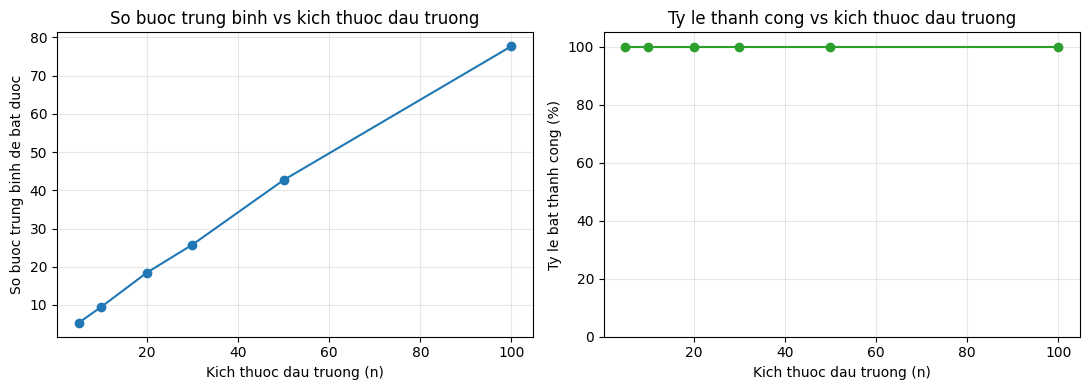

In [15]:
# --- Experiments with the model-based hunter ---

def run_experiment(hunter_agent_factory, monster_agent_function, n, max_steps, n_runs=100):
    """Run n_runs simulations, creating a *new* hunter agent (fresh memory)
    for every run, and return (success_rate, avg_steps_successful, n_failed)."""
    results = []
    for _ in range(n_runs):
        hunter_agent_function = hunter_agent_factory()
        result = arena_environment(hunter_agent_function, monster_agent_function,
                                    n=n, max_steps=max_steps, visualize=False)
        results.append(result)
    results = np.array(results, dtype=float)
    n_failed = int(np.sum(np.isnan(results)))
    n_success = n_runs - n_failed
    success_rate = n_success / n_runs
    avg_steps = np.nanmean(results)
    return success_rate, avg_steps, n_failed


# First, pick a good `recheck_interval` by comparing a few values on a 10x10 arena
print("Tuning recheck_interval on a 10x10 arena (100 runs each):")
for interval in [3, 5, 8, 15]:
    sr, avg, failed = run_experiment(
        lambda interval=interval: make_model_based_hunter(recheck_interval=interval),
        monster_agent_function_simple, n=10, max_steps=150, n_runs=100)
    print(f"  recheck_interval={interval:2d}: success rate={sr*100:5.1f}%, "
          f"avg steps={avg:6.2f}, failed={failed}")

# recheck_interval=5 gives a good balance -> use it for the main experiments
RECHECK_INTERVAL = 5

# De bai chi yeu cau "it nhat 100 lan chay o dau truong 10x10 va 30x30".
# O day minh chay VUOT muc toi thieu: 300 lan/cau hinh (thay vi 100), va
# THEM nhieu kich thuoc dau truong hon (5, 20, 50, 100) ngoai 2 kich thuoc
# bat buoc, de thay ro xu huong so buoc trung binh tang theo kich thuoc
# dau truong nhu the nao, thay vi chi co 2 diem du lieu roi rac.
print("\nMain experiment (300 runs moi cau hinh, vuot muc toi thieu 100 lan de bai yeu cau):")
arena_sizes = [5, 10, 20, 30, 50, 100]
results_table = {}
for n in arena_sizes:
    max_steps = max(200, 8 * n)
    sr, avg, failed = run_experiment(
        lambda: make_model_based_hunter(recheck_interval=RECHECK_INTERVAL),
        monster_agent_function_simple, n=n, max_steps=max_steps, n_runs=300)
    results_table[n] = (sr, avg, failed)
    print(f"Arena {n:3d}x{n:<3d}: success rate = {sr*100:5.1f}%, "
          f"avg steps (successful runs) = {avg:6.2f}, failed = {failed}/300")



sizes = list(results_table.keys())
avg_steps_list = [results_table[n][1] for n in sizes]
success_list = [results_table[n][0] * 100 for n in sizes]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(sizes, avg_steps_list, marker='o', color='tab:blue')
ax1.set_xlabel("Kich thuoc dau truong (n)")
ax1.set_ylabel("So buoc trung binh de bat duoc")
ax1.set_title("So buoc trung binh vs kich thuoc dau truong")
ax1.grid(True, alpha=0.3)

ax2.plot(sizes, success_list, marker='o', color='tab:green')
ax2.set_xlabel("Kich thuoc dau truong (n)")
ax2.set_ylabel("Ty le bat thanh cong (%)")
ax2.set_title("Ty le thanh cong vs kich thuoc dau truong")
ax2.set_ylim(0, 105)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Your Conclusion [4 points] 

Discuss the following:

* What is your hunter's final strategy to choose actions. Why does it work well?
* Do you use teleportation. Why and in what situation? Why not?
* How does the arena size affects your hunter agent's performance?

* What is your hunter's final strategy to choose actions. Why does it work well?
Chiến lược của Hunter được xây dựng theo mô hình model-based reflex agent. Ban đầu, Hunter sử dụng hành động listen để nhận biết vị trí hiện tại của Monster (self.monster_pos). Thông tin này được lưu vào trạng thái bên trong của tác tử, sau đó Hunter dựa trên vị trí của bản thân và vị trí của Monster đã được lưu đó để lựa chọn hành động tiếp theo: 
+ Nếu Monster nằm phía trên Hunter → chọn north.
+ Nếu Monster nằm phía dưới Hunter → chọn south.
+ Nếu Monster nằm bên trái Hunter → chọn west.
+ Nếu Monster nằm bên phải Hunter → chọn east.
Khi Monster vẫn còn cách Hunter ở cả hàng và cột, Hunter ưu tiên hướng giúp giảm khoảng cách đến Monster. Vì vậy, thay vì lựa chọn hành động ngẫu nhiên, mỗi bước di chuyển đều hướng Hunter đến gần vị trí Monster hơn.
Chiến lược này hoạt động hiệu quả vì Hunter không phải tìm kiếm Monster một cách ngẫu nhiên. Sau khi sử dụng listen, tác tử đã có thông tin về vị trí mục tiêu và có thể sử dụng thông tin đó để đưa ra hành động phù hợp. Do đó, số bước cần thiết để bắt Monster thường thấp hơn so với tác tử ngẫu nhiên.
Việc sử dụng teleport
* * Do you use teleportation. Why and in what situation? Why not? 
Agent của em không sử dụng teleport. Bởi vì teleport đưa hunter đến một ô ngẫu nhiên. Trong khi đó, sau khi sử dụng listen, Hunter đã biết vị trí của Hunter. Vì vậy, việc di chuyển trực tiếp theo hướng có sẵn làm giảm khoảng cách đến Monster sẽ có tính định hướng cao hơn. Do đó, trong chiến lược này, teleport không được ưu tiên sử dụng. Tuy nhiên, teleport vấn rất hữu ích với trường hợp, Hunter ở rất xa so với mục tiêu. Vì nó mang tính ngẫu nhiên nên tùy vào độ may mắn. Nếu may thì từ vị trí rất xa Hunter được di chuyển đến gần mục tiêu hơn. Còn nếu không may thì bị di chuyển xa hơn lúc đầu.
* How does the arena size affects your hunter agent's performance?
Trong Arena 10×10, không gian tìm kiếm nhỏ hơn nên khoảng cách giữa Hunter và Monster thường không quá lớn. Sau khi biết vị trí Monster bằng listen, Hunter có thể nhanh chóng di chuyển về phía mục tiêu. Vì vậy, tác tử có xu hướng bắt Monster trong ít bước hơn và có khả năng hoàn thành nhiệm vụ trong giới hạn số bước cao hơn.
Khi tăng kích thước lên 30×30, không gian hoạt động lớn hơn đáng kể. Hunter và Monster có thể xuất hiện ở những vị trí cách xa nhau hơn. Mặc dù chiến lược của Hunter vẫn chọn hướng làm giảm khoảng cách ở mỗi bước, tác tử vẫn cần nhiều bước hơn để tiếp cận Monster. Nếu số bước tối đa (max_steps) không tăng tương ứng với kích thước Arena, khả năng Hunter không bắt được Monster trong giới hạn cho phép có thể tăng lên, được thể hiện bằng kết quả nan

The monster is also an agent. Describe how the monster's agent function could be changed so it gets better at avoiding the hunter.

Nếu được cải tiến monster_agent. thì thay vì chọn ngẫu nhiên các action như hiện tại, Monster nên quan sát vị trí của Hunter, sau đó chọn hướng làm tăng khoảng cách giữa Monster và Hunter
Ngoài ra, Monster cũng có thể di chuyển ngẫu nhiên để Hunter khó định hướng để đuổi theo

# More Work (Optional)

Here are some ideas:

* Implement a better monster agent function and perform experiments
* Change the environment so multiple hunters can hunt the monster.
* Give the hunter a new action that shoots an arrow in a specific direction. 
  The arrow can go a maximum of 5 squares. If the hunter hits the monster, then it wins.

## More Work: Ý 1 - Monster thông minh hơn (tùy chọn, làm thêm ngoài yêu cầu)

Theo đúng ý đã đề xuất ở phần Conclusion: thay vì di chuyển hoàn toàn ngẫu nhiên, monster giờ sẽ
**quan sát vị trí hunter** và, khi hunter ở gần, chủ động di chuyển theo hướng **làm tăng khoảng
cách** giữa hai bên (chạy trốn). Khi hunter ở xa, monster vẫn giữ hành vi ngẫu nhiên như cũ (chủ
yếu đứng yên) để không bị lộ vị trí một cách không cần thiết.


In [16]:
def monster_agent_function_smart(hunter_pos, monster_pos, flee_distance=5, flee_prob=0.8):
    """
    Monster thong minh hon (model-based o phia monster):
    - Neu hunter dang o gan (khoang cach Manhattan <= flee_distance), monster chon huong
      di chuyen LAM TANG khoang cach toi hunter (chay tron), voi xac suat flee_prob.
    - Con lai (hunter o xa, hoac 20% con lai de kho doan), monster hanh xu nhu agent don gian
      cu: chu yeu dung yen, thinh thoang di ngau nhien 1 huong.
    """
    dr = int(monster_pos[0] - hunter_pos[0])   # > 0: monster dang o phia nam so voi hunter
    dc = int(monster_pos[1] - hunter_pos[1])   # > 0: monster dang o phia dong so voi hunter
    distance = abs(dr) + abs(dc)

    if distance <= flee_distance and np.random.random() < flee_prob:
        # chon 1 trong toi da 2 huong lam TANG khoang cach, roi random giua chung
        away_options = []
        away_options.append('south' if dr >= 0 else 'north')
        away_options.append('east' if dc >= 0 else 'west')
        return np.random.choice(away_options)
    else:
        return np.random.choice(monster_actions, p=[0.125, 0.125, 0.125, 0.125, 0.5])


# thu nhanh 1 van co hinh anh de kiem tra monster co chay tron dung khong
np.random.seed(1)
arena_environment(make_model_based_hunter(recheck_interval=5), monster_agent_function_smart,
                   n=10, max_steps=40, visualize=True, animation=False)


Step 1: Hunter is at '[5 0]'; Monster is at '[5 8]'
..........
..........
..........
..........
..........
H.......M.
..........
..........
..........
..........
Hunter chose action 'listen'
Monster chose action 'north'


Step 2: Hunter is at '[5 0]'; Monster is at '[4 8]'
..........
..........
..........
..........
........M.
H.........
..........
..........
..........
..........
Hunter chose action 'east'
Monster chose action 'east'


Step 3: Hunter is at '[5 1]'; Monster is at '[4 9]'
..........
..........
..........
..........
.........M
.H........
..........
..........
..........
..........
Hunter chose action 'east'
Monster chose action 'west'


Step 4: Hunter is at '[5 2]'; Monster is at '[4 8]'
..........
..........
..........
..........
........M.
..H.......
..........
..........
..........
..........
Hunter chose action 'east'
Monster chose action 'south'


Step 5: Hunter is at '[5 3]'; Monster is at '[5 8]'
..........
..........
..........
..........
..........
...H....M.
..

21

In [17]:
# --- So sanh hunter cua ban doi dau voi monster CU (ngau nhien) va monster MOI (biet chay tron) ---

print("So sanh hieu nang khi monster thong minh hon (100 lan chay moi cau hinh):\n")

for n, max_steps in [(10, 150), (30, 400)]:
    sr_simple, avg_simple, fail_simple = run_experiment(
        lambda: make_model_based_hunter(recheck_interval=5),
        monster_agent_function_simple, n=n, max_steps=max_steps, n_runs=100)
    sr_smart, avg_smart, fail_smart = run_experiment(
        lambda: make_model_based_hunter(recheck_interval=5),
        monster_agent_function_smart, n=n, max_steps=max_steps, n_runs=100)

    print(f"Arena {n}x{n}:")
    print(f"  Monster CU (ngau nhien)   -> success={sr_simple*100:5.1f}%, avg steps={avg_simple:6.2f}, failed={fail_simple}")
    print(f"  Monster MOI (biet chay)   -> success={sr_smart*100:5.1f}%, avg steps={avg_smart:6.2f}, failed={fail_smart}")
    print(f"  => Monster moi lam hunter mat gap {avg_smart/avg_simple:.2f} lan so buoc de bat duoc.\n")


So sanh hieu nang khi monster thong minh hon (100 lan chay moi cau hinh):

Arena 10x10:
  Monster CU (ngau nhien)   -> success=100.0%, avg steps=  9.69, failed=0
  Monster MOI (biet chay)   -> success=100.0%, avg steps= 20.57, failed=0
  => Monster moi lam hunter mat gap 2.12 lan so buoc de bat duoc.

Arena 30x30:
  Monster CU (ngau nhien)   -> success=100.0%, avg steps= 28.17, failed=0
  Monster MOI (biet chay)   -> success=100.0%, avg steps= 62.02, failed=0
  => Monster moi lam hunter mat gap 2.20 lan so buoc de bat duoc.



**Nhận xét:** Monster thông minh hơn (biết chạy trốn khi hunter ở gần) khiến hunter mất số bước
trung bình **cao hơn rõ rệt** so với monster ngẫu nhiên (khoảng gấp đôi ở cả hai kích thước đấu
trường), dù tỷ lệ bắt được cuối cùng vẫn là 100% vì đấu trường hữu hạn và hunter luôn bám đuổi có
định hướng — monster không thể chạy trốn mãi mãi vì sớm muộn cũng bị dồn vào góc hoặc cạnh đấu
trường. Điều này cho thấy: dù chỉ thêm một luật phản xạ đơn giản ("thấy gần thì chạy xa ra") cho
monster, độ khó của trò chơi đã tăng lên đáng kể — minh chứng cho việc ngay cả một *simple reflex
agent* phía monster cũng đủ để thay đổi cán cân giữa hai bên trong trò chơi truy đuổi này.


# Bonus: Trực quan hóa đẹp hơn bằng HTML/Emoji (tùy chọn, không tính điểm)

Hàm `print_arena()` có sẵn trong `arena_environment` chỉ in ra chữ (dấu `.`, `H`, `M`).
Phần dưới đây là code **thêm ngoài yêu cầu đề bài**, dùng `IPython.display.HTML` để vẽ đấu
trường bằng emoji giống ảnh minh họa trong đề, chỉ để xem cho trực quan/demo, không ảnh hưởng
điểm số nếu không dùng.


In [25]:
from IPython.display import display, HTML, clear_output
from time import sleep

from IPython.display import display, HTML

def render_arena_html(
    n,
    hunter_pos,
    monster_pos,
    cell_size=50,
    hunter_img="./images/hunter.png",
    monster_img="./images/monster.png"
):
    """Vẽ đấu trường n x n với hình Hunter và Monster."""

    total_w = n * (cell_size + 3) + 10
    cells_html = ""

    for row in range(n):
        for col in range(n):

            content = ""

            # Hunter và Monster cùng vị trí
            if [row, col] == list(hunter_pos) and [row, col] == list(monster_pos):
                content = f'''
                <img src="{hunter_img}"
                     style="width:{cell_size*0.75}px;
                            height:{cell_size*0.75}px;
                            object-fit:contain;">
                '''

            # Hunter
            elif [row, col] == list(hunter_pos):
                content = f'''
                <img src="{hunter_img}"
                     style="width:{cell_size*0.75}px;
                            height:{cell_size*0.75}px;
                            object-fit:contain;">
                '''

            # Monster
            elif [row, col] == list(monster_pos):
                content = f'''
                <img src="{monster_img}"
                     style="width:{cell_size*0.75}px;
                            height:{cell_size*0.75}px;
                            object-fit:contain;">
                '''

            cells_html += f'<div class="cell">{content}</div>'

    html = f"""
    <style>

    .grid {{
        display: flex;
        flex-wrap: wrap;
        width: {total_w}px;
        background: black;
        padding: 5px;
        border: 5px solid black;
    }}

    .cell {{
        width: {cell_size}px;
        height: {cell_size}px;
        margin: 1.5px;

        background: radial-gradient(
            circle,
            #4a6b3a 0%,
            #33502a 100%
        );

        display: flex;
        align-items: center;
        justify-content: center;

        box-sizing: border-box;
    }}

    .cell img {{
        display: block;
    }}

    </style>

    <div class="grid">
        {cells_html}
    </div>
    """

    display(HTML(html))


def watch_hunt(hunter_agent_function, monster_agent_function, n=10, max_steps=30, delay=0.4):
    """Chạy 1 ván và vẽ lại đấu trường sau mỗi bước (giống animation=True nhưng có hình)."""
    monster_pos = np.random.randint(0, n-1, size=2)
    hunter_pos = np.random.randint(0, n-1, size=2)
    hunter_action = None

    def move(action, position):
        if action == 'north': position[0] -= 1
        elif action == 'south': position[0] += 1
        elif action == 'west': position[1] -= 1
        elif action == 'east': position[1] += 1
        return np.clip(position, 0, n-1)

    for step in range(max_steps):
        clear_output(wait=True)
        render_arena_html(n, hunter_pos, monster_pos)
        print(f"Bước {step + 1}")

        if np.array_equal(hunter_pos, monster_pos):
            print("Hunter bắt được Monster rồi! 🎉")
            return step

        monster_action = monster_agent_function(hunter_pos, monster_pos)
        if monster_action != 'stay':
            monster_pos = move(monster_action, monster_pos)

        monster_pos_instrument = monster_pos if hunter_action == 'listen' else None
        hunter_action = hunter_agent_function(hunter_pos, monster_pos_instrument)
        if hunter_action == 'teleport':
            hunter_pos = np.random.randint(0, n-1, size=2)
        elif hunter_action != 'listen':
            hunter_pos = move(hunter_action, hunter_pos)

        sleep(delay)

    print("Hunter không bắt được trong giới hạn bước.")
    return np.nan


In [26]:
# Demo: xem model-based hunter của bạn "săn" quái vật bằng hình ảnh
watch_hunt(make_model_based_hunter(recheck_interval=5), monster_agent_function_simple,
           n=10, max_steps=30, delay=0.4)


Bước 16
Hunter bắt được Monster rồi! 🎉


15